# Melanoma Screening — ResNet50 + Gradio front end

Transfer-learning pipeline over a lesion-image folder in Google Drive, with a Gradio web UI for
checking a single photo.

**Cell order matters.** The front end in the last section reads `model`, `class_names` and the test
metrics from the session, so run the training and evaluation cells first. It will still work on its
own — it falls back to loading the saved `.keras` file from Drive — but the "About the model" panel
won't show the test metrics in that case.

**Data layout:** `Dataset Images` should contain one subfolder per class. Nothing hardcodes the class
count — it is read from the folders — but the screening UI needs to know which folder is the
melanoma one, and finds it by name (see `MAL_IDX` in the last cell).

```
Dataset Images/
    benign/
    malignant/
    <third class>/
```


## Mount Google Drive to access data

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


## Import functions and perform GPU check

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score, classification_report,
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Load and prepare data

`label_mode='int'` gives integer labels (0, 1, 2, ...), which pairs with
`sparse_categorical_crossentropy` during training.


In [3]:
DATA_DIR = '/content/drive/MyDrive/Dataset Images'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32   # drop to 16 if ResNet50 runs out of GPU memory
SEED = 123

# 70% train
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
)

# 30% held out -> split into validation + test below
holdout_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

holdout_batches = holdout_ds.cardinality().numpy()
val_ds = holdout_ds.take(holdout_batches // 2)
test_ds = holdout_ds.skip(holdout_batches // 2)

print(f"Train batches: {train_ds.cardinality().numpy()}, "
      f"Val batches: {val_ds.cardinality().numpy()}, "
      f"Test batches: {test_ds.cardinality().numpy()}")


Found 17475 files belonging to 3 classes.
Using 12233 files for training.
Found 17475 files belonging to 3 classes.
Using 5242 files for validation.
Classes: ['ALM', 'Benign', 'Melanoma']
Number of classes: 3
Train batches: 383, Val batches: 82, Test batches: 82


In [4]:
# Check how many images are in each class - useful for spotting imbalance
import pathlib

data_path = pathlib.Path(DATA_DIR)
for name in class_names:
    n = len(list((data_path / name).glob('*')))
    print(f"{name}: {n} images")


ALM: 337 images
Benign: 12839 images
Melanoma: 4299 images


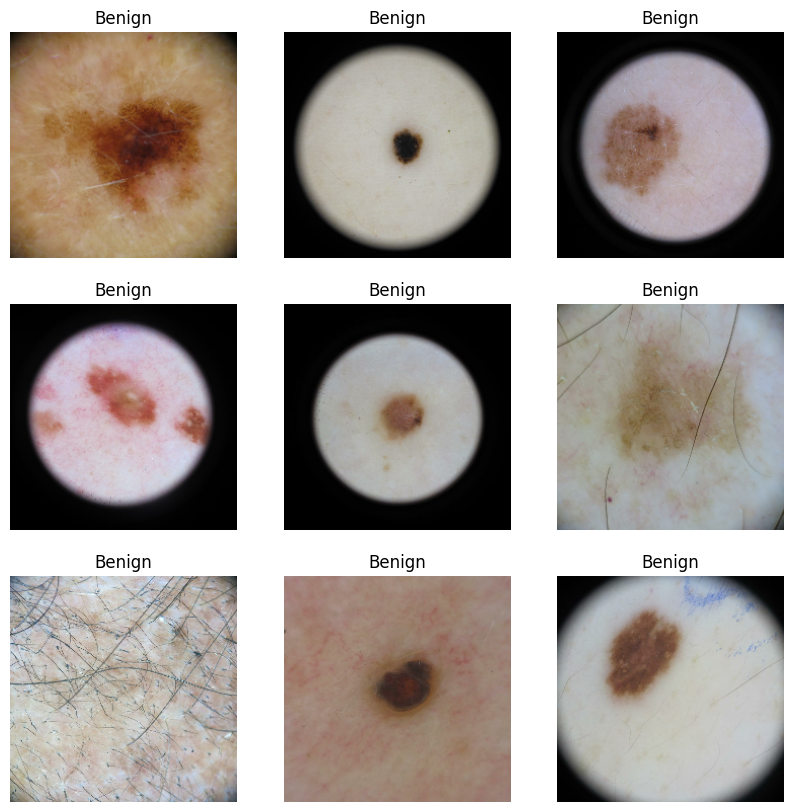

In [5]:
# Preview a few images
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")


In [6]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE

# Augmentation is applied only to the training set. Validation/test stay untouched
# so evaluation reflects real, unaugmented images.
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)

val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


## Load ResNet50 base pretrained on ImageNet, frozen

In [7]:
IMG_SHAPE = IMG_SIZE + (3,)

base_model = tf.keras.applications.ResNet50(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet',
)
base_model.trainable = False  # freeze the pretrained base

base_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

## Classification head implementation

The output layer has one unit per class with a **softmax** activation, so the outputs form a
probability distribution summing to 1.

`resnet50.preprocess_input` must match the backbone above: it converts RGB to BGR and subtracts the
ImageNet channel means. Leaving MobileNetV2's preprocessing here would not raise an error, it would
just train badly.


In [8]:
inputs = tf.keras.Input(shape=IMG_SHAPE)

# ResNet50's own preprocessing (RGB -> BGR, ImageNet mean subtraction)
x = tf.keras.applications.resnet50.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)   # 2048-dim for ResNet50
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 3)         │      6,147 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## Model training

`sparse_categorical_crossentropy` is the multi-class counterpart to binary crossentropy and expects the
integer labels from `label_mode='int'`.

Keras's `AUC` metric does not accept sparse multi-class labels, so AUC is computed with scikit-learn in
the evaluation section instead of being tracked during training.

If your classes are imbalanced (check the counts printed above), uncomment the `class_weight` block.


In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/melanoma_resnet50_best.keras',
        monitor='val_loss', save_best_only=True,
    ),
]

# Optional: weight the loss by class frequency if your dataset is imbalanced.
# from sklearn.utils.class_weight import compute_class_weight
# train_labels = np.concatenate([y.numpy() for _, y in train_ds])
# weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels)
# class_weight = dict(enumerate(weights))
# print("Class weights:", class_weight)

EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    # class_weight=class_weight,  # uncomment together with the block above
)


Epoch 1/20
383/383 ━━━━━━━━━━━━━━━━━━━━ 4824s 13s/step - accuracy: 0.6823 - loss: 0.7985 - val_accuracy: 0.7691 - val_loss: 0.5822
Epoch 2/20
383/383 ━━━━━━━━━━━━━━━━━━━━ 217s 566ms/step - accuracy: 0.7470 - loss: 0.6337 - val_accuracy: 0.7873 - val_loss: 0.5495
Epoch 3/20
383/383 ━━━━━━━━━━━━━━━━━━━━ 191s 498ms/step - accuracy: 0.7678 - loss: 0.5851 - val_accuracy: 0.7965 - val_loss: 0.5299
Epoch 4/20
383/383 ━━━━━━━━━━━━━━━━━━━━ 184s 480ms/step - accuracy: 0.7695 - loss: 0.5612 - val_accuracy: 0.7957 - val_loss: 0.5185
Epoch 5/20
383/383 ━━━━━━━━━━━━━━━━━━━━ 199s 473ms/step - accuracy: 0.7801 - loss: 0.5499 - val_accuracy: 0.7961 - val_loss: 0.5194
Epoch 6/20
383/383 ━━━━━━━━━━━━━━━━━━━━ 182s 474ms/step - accuracy: 0.7854 - loss: 0.5248 - val_accuracy: 0.7992 - val_loss: 0.5020
Epoch 7/20
383/383 ━━━━━━━━━━━━━━━━━━━━ 182s 473ms/step - accuracy: 0.7887 - loss: 0.5195 - val_accuracy: 0.8022 - val_loss: 0.4890
Epoch 8/20
383/383 ━━━━━━━━━━━━━━━━━━━━ 181s 471ms/step - accuracy: 0.7949 - 

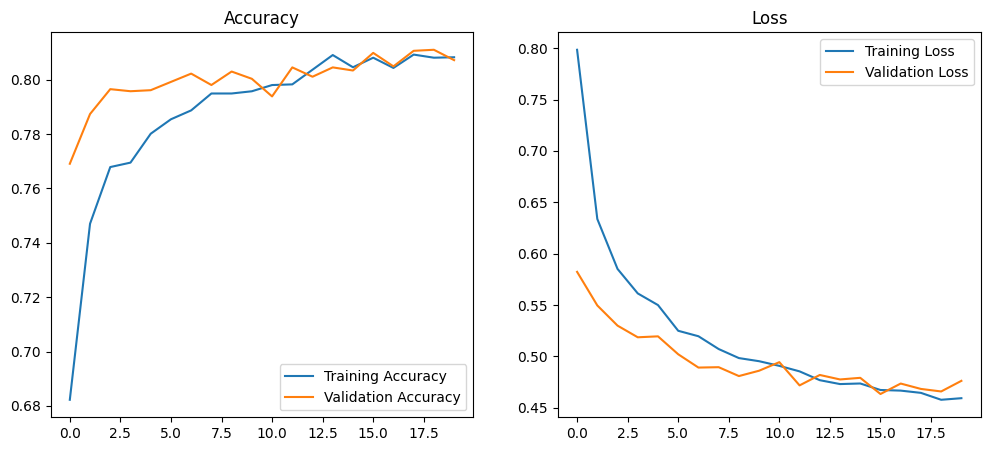

In [10]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(loss))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Loss')

plt.show()


## Model evaluation

With more than two classes a single ROC curve no longer applies. The standard approach is
**one-vs-rest**: each class in turn is treated as positive against all the others, giving one curve and
one AUC per class, plus a macro average.


In [11]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")


82/82 ━━━━━━━━━━━━━━━━━━━━ 794s 10s/step - accuracy: 0.8144 - loss: 0.4636
Test loss: 0.4636 | Test accuracy: 0.8144


In [12]:
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_pred_prob = model.predict(test_ds)          # shape: (n_samples, NUM_CLASSES)
y_pred = np.argmax(y_pred_prob, axis=1)       # highest-probability class

print(classification_report(y_true, y_pred, target_names=class_names))


82/82 ━━━━━━━━━━━━━━━━━━━━ 30s 189ms/step
              precision    recall  f1-score   support

         ALM       0.00      0.00      0.00        54
      Benign       0.73      0.85      0.79      1932
    Melanoma       0.20      0.10      0.14       632

    accuracy                           0.66      2618
   macro avg       0.31      0.32      0.31      2618
weighted avg       0.59      0.66      0.61      2618



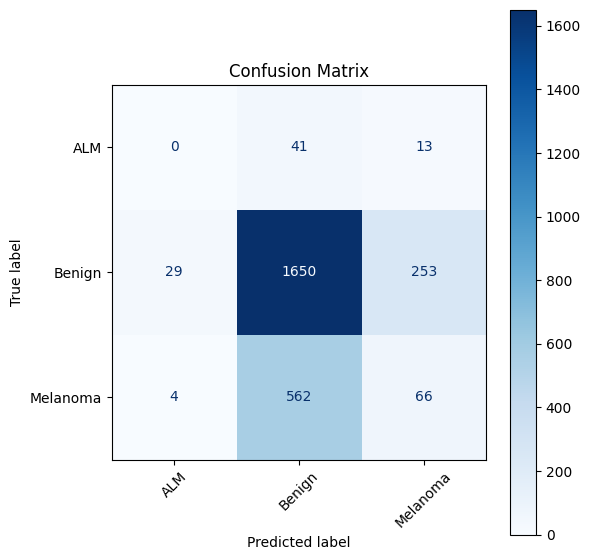

In [13]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()


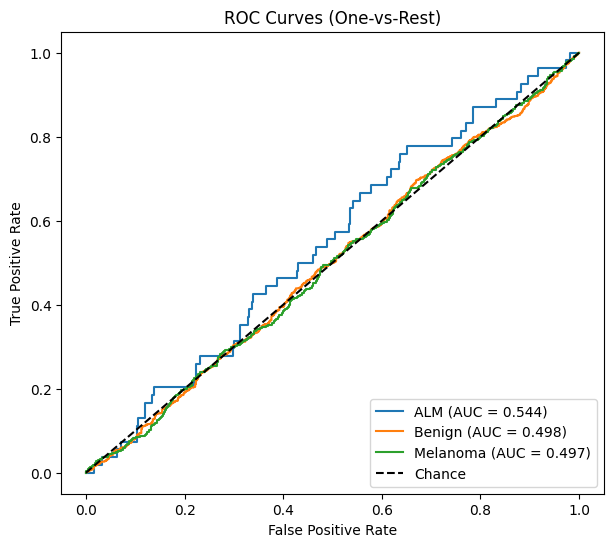

Macro-average one-vs-rest AUC: 0.5131


In [14]:
# One-vs-rest ROC curve: one curve per class
y_true_bin = label_binarize(y_true, classes=np.arange(NUM_CLASSES))

plt.figure(figsize=(7, 6))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (One-vs-Rest)')
plt.legend(loc='lower right')
plt.show()

macro_auc = roc_auc_score(y_true, y_pred_prob, multi_class='ovr', average='macro')
print(f"Macro-average one-vs-rest AUC: {macro_auc:.4f}")


## Melanoma screening website (Gradio front end)

Run this cell **after** the training and evaluation cells so it picks up `model`, `class_names` and the
test metrics from the session. On its own it falls back to the saved model on Drive.

With more than two classes the UI reports two things: the **predicted class** (highest softmax
probability) and the **melanoma likelihood** (the softmax probability of the melanoma class
specifically), which is what drives the risk banding. Check the printed `MAL_IDX` line to confirm the
right folder was identified as melanoma.


In [ ]:
# ============================================================
#  Melanoma screening website (Gradio front end) for Google Colab
#  Put this in the LAST cell of the notebook and run it AFTER
#  the training cells (or on its own to use the saved model).
# ============================================================
!pip install -q gradio

import os
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image
from tensorflow.keras import layers

# ------------------------------------------------------------
# 1) CONNECT TO YOUR BACKEND (model + image database on Drive)
# ------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Dataset Images'
MODEL_PATH = '/content/drive/MyDrive/melanoma_resnet50_best.keras'
IMG_SIZE = (224, 224)
SHOW_SIMILAR_CASES = True   # set False to skip building the similar-images index

if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

# Use the model trained in this session, or load the saved best model from Drive.
if 'model' not in globals():
    print("Loading saved model from Drive...")
    model = tf.keras.models.load_model(MODEL_PATH)

# Same class order Keras used during training (alphabetical folder names).
if 'class_names' not in globals():
    class_names = sorted(d for d in os.listdir(DATA_DIR)
                         if os.path.isdir(os.path.join(DATA_DIR, d)))
NUM_CLASSES = len(class_names)

# Which folder holds the melanoma / malignant cases? Its softmax probability
# drives the risk banding below, so check this line prints what you expect.
MAL_IDX = next((i for i, n in enumerate(class_names)
                if 'malig' in n.lower() or 'melan' in n.lower()), None)
if MAL_IDX is None:
    MAL_IDX = NUM_CLASSES - 1
    print(f"WARNING: no class name looks like melanoma. Falling back to "
          f"'{class_names[MAL_IDX]}' - set MAL_IDX by hand if that is wrong.")
print(f"Classes: {class_names} -> treating '{class_names[MAL_IDX]}' as melanoma")


def to_model_input(image: Image.Image) -> np.ndarray:
    # Raw 0-255 pixels: your model applies ResNet50 preprocess_input itself.
    img = image.convert("RGB").resize(IMG_SIZE)
    return np.expand_dims(np.asarray(img, dtype=np.float32), 0)


def predict_probabilities(image: Image.Image) -> np.ndarray:
    # Softmax vector over all classes, in class_names order.
    return model.predict(to_model_input(image), verbose=0)[0]


# ------------------------------------------------------------
# 2) SIMILAR CASES FROM THE IMAGE DATABASE
#    Uses the ResNet50 features to find look-alike images in DATA_DIR.
# ------------------------------------------------------------
db_paths, db_labels, db_feats, feature_extractor = [], None, None, None

if SHOW_SIMILAR_CASES:
    print("Indexing image database for similar cases (one-time, may take a minute)...")
    base = tf.keras.applications.ResNet50(input_shape=IMG_SIZE + (3,),
                                          include_top=False, weights='imagenet')
    inp = tf.keras.Input(shape=IMG_SIZE + (3,))
    feat = layers.GlobalAveragePooling2D()(
        base(tf.keras.applications.resnet50.preprocess_input(inp), training=False))
    feature_extractor = tf.keras.Model(inp, feat)

    index_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR, image_size=IMG_SIZE, batch_size=64,
        label_mode='int', shuffle=False)
    db_paths = index_ds.file_paths

    feats, labs = [], []
    for x, y in index_ds:
        feats.append(feature_extractor(x, training=False).numpy())
        labs.append(y.numpy().ravel().astype(int))
    db_feats = np.concatenate(feats)
    db_feats /= np.linalg.norm(db_feats, axis=1, keepdims=True) + 1e-8
    db_labels = np.concatenate(labs)
    print(f"Indexed {len(db_paths)} images.")


def find_similar(image, k=4):
    if feature_extractor is None:
        return []
    q = feature_extractor(to_model_input(image), training=False).numpy()[0]
    q /= np.linalg.norm(q) + 1e-8
    sims = db_feats @ q
    top = np.argsort(-sims)[:k]
    results = []
    for i in top:
        label = class_names[db_labels[i]].capitalize()
        img = Image.open(db_paths[i]).convert("RGB")
        img.thumbnail((300, 300))
        results.append((img, f"{label} | {round(float(sims[i]) * 100)}% similar"))
    return results


# ------------------------------------------------------------
# 3) RESULT LOGIC
# ------------------------------------------------------------
EMPTY_HTML = ("<div class='empty'>Upload a close-up photo of the skin spot, then select "
              "<b>Analyze image</b>.</div>")


def analyze(image):
    if image is None:
        return EMPTY_HTML, None, []

    try:
        probs = predict_probabilities(image)
        similar = find_similar(image)
    except Exception as e:
        return f"<div class='card error'>The model could not process this image: {e}</div>", None, []

    p = float(probs[MAL_IDX])                 # melanoma likelihood
    predicted = class_names[int(np.argmax(probs))].capitalize()

    if p >= 0.5:
        level, cls = "Higher risk", "high"
        advice = ("Features in this image resemble melanoma. Book an appointment with a "
                  "dermatologist or GP soon and show them this spot.")
    elif p >= 0.3:
        level, cls = "Uncertain", "mid"
        advice = ("The result is borderline. Have the spot checked by a doctor, especially "
                  "if it has changed in size, shape or colour.")
    else:
        level, cls = "Lower risk", "low"
        advice = ("No strong melanoma features were detected. Keep monitoring the spot and "
                  "see a doctor if it changes, bleeds or itches.")

    pct = round(p * 100)
    html = f"""
    <div class='card {cls}'>
      <p class='level'>{level}</p>
      <p class='score'>{pct}<span>% melanoma likelihood</span></p>
      <div class='bar'><div style='width:{pct}%'></div></div>
      <p class='predicted'>Closest match: <b>{predicted}</b></p>
      <p class='advice'>{advice}</p>
    </div>"""
    confidences = {name: float(probs[i]) for i, name in enumerate(class_names)}
    return html, confidences, similar


# Model facts for the "About the model" panel (filled in if training ran this session)
about = [f"ResNet50 (ImageNet pretrained) fine-tuned to classify "
         f"{', '.join(c.capitalize() for c in class_names)}."]
if db_paths:
    about.append(f"Image database: {len(db_paths):,} labelled images.")
if 'test_acc' in globals():
    line = f"Held-out test accuracy: {test_acc:.1%}."
    if 'macro_auc' in globals():
        line += f" Macro one-vs-rest AUC: {macro_auc:.3f}."
    about.append(line)
about.append("Similar cases are matched by visual appearance and are shown for context, "
             "not as a diagnosis.")
ABOUT = "\n\n".join(about)

# ------------------------------------------------------------
# 4) DESIGN
# ------------------------------------------------------------
CSS = """
@import url('https://fonts.googleapis.com/css2?family=Source+Serif+4:opsz,wght@8..60,500;8..60,600&family=IBM+Plex+Sans:wght@400;500;600&display=swap');

:root { --ink:#1C2B39; --muted:#5B6B78; --paper:#F4F7F8; --teal:#1F6F78;
        --low:#2E7D5B; --mid:#B7791F; --high:#B23A2E; }

.gradio-container { max-width: 1080px !important; margin: auto !important;
  font-family: 'IBM Plex Sans', system-ui, sans-serif !important; background: var(--paper) !important; }

#hero { padding: 40px 8px 16px; }
#hero h1 { font-family: 'Source Serif 4', Georgia, serif; font-weight: 600;
  font-size: clamp(2rem, 4vw, 2.9rem); line-height: 1.1; color: var(--ink); margin: 0 0 12px; }
#hero p { color: var(--muted); font-size: 1.05rem; max-width: 60ch; line-height: 1.55; margin: 0; }

#lens { border: none !important; background: transparent !important; }
#lens img { border-radius: 50%; aspect-ratio: 1 / 1; object-fit: cover;
  box-shadow: 0 0 0 10px #fff, 0 0 0 11px #cfd9dd; }

#analyze { background: var(--teal) !important; color: #fff !important; border: none !important;
  font-weight: 600; font-size: 1rem; }
#analyze:hover { filter: brightness(1.1); }

.card { background: #fff; border-radius: 14px; padding: 24px 26px; border-left: 6px solid var(--teal); }
.card.low { border-left-color: var(--low); }  .card.mid { border-left-color: var(--mid); }
.card.high { border-left-color: var(--high); }
.card.error { border-left-color: var(--high); color: var(--high); }
.level { font-weight: 600; font-size: 1.1rem; margin: 0; color: var(--ink); }
.low .level { color: var(--low); } .mid .level { color: var(--mid); } .high .level { color: var(--high); }
.score { font-family: 'Source Serif 4', Georgia, serif; font-size: 3.2rem; margin: 6px 0 10px;
  color: var(--ink); line-height: 1; }
.score span { font-family: 'IBM Plex Sans', sans-serif; font-size: 1rem; color: var(--muted); margin-left: 8px; }
.bar { height: 8px; background: #E3EAED; border-radius: 4px; overflow: hidden; }
.bar div { height: 100%; background: var(--teal); transition: width .6s ease; }
.low .bar div { background: var(--low); } .mid .bar div { background: var(--mid); }
.high .bar div { background: var(--high); }
.predicted { color: var(--muted); font-size: .95rem; margin: 14px 0 0; }
.predicted b { color: var(--ink); }
.advice { color: var(--ink); line-height: 1.55; margin: 10px 0 0; }
.empty { color: var(--muted); padding: 28px; border: 1.5px dashed #c5d1d6; border-radius: 14px;
  text-align: center; line-height: 1.5; }

#similar h3 { font-family: 'Source Serif 4', Georgia, serif; color: var(--ink); margin: 24px 0 4px; }
#similar p { color: var(--muted); margin: 0 0 8px; }

#notice { font-size: .88rem; color: var(--muted); line-height: 1.5;
  border-top: 1px solid #d8e1e5; padding-top: 18px; margin-top: 8px; }
@media (prefers-reduced-motion: reduce) { .bar div { transition: none; } }
"""

THEME = gr.themes.Soft(primary_hue="teal", neutral_hue="slate")

ABCDE = """
Doctors often check moles using the **ABCDE** signs:

- **Asymmetry:** one half doesn't match the other.
- **Border:** edges are ragged, notched or blurred.
- **Colour:** several shades of brown, black, red, white or blue.
- **Diameter:** larger than about 6 mm (a pencil eraser).
- **Evolving:** any change in size, shape, colour, itching or bleeding.
"""

TIPS = """
- Use natural light and hold the camera 10 to 15 cm from the skin.
- Keep the spot centred and in sharp focus.
- Crop out clothing, jewellery and background where possible.
- One spot per photo.
"""

NOTICE = """
**Important:** this tool is for education and research only. It is not a medical device and
cannot diagnose skin cancer. Always have a doctor examine any spot that worries you.
In Australia, you can find a GP or skin check clinic through healthdirect.gov.au.
"""

# ------------------------------------------------------------
# 5) LAYOUT
# ------------------------------------------------------------
GRADIO_6 = int(gr.__version__.split(".")[0]) >= 6
blocks_kwargs = {} if GRADIO_6 else {"css": CSS, "theme": THEME}

with gr.Blocks(title="Skin Spot Check | Melanoma Screening", **blocks_kwargs) as demo:
    gr.HTML("""
      <div id='hero'>
        <h1>Check a skin spot for signs of melanoma</h1>
        <p>Upload a clear photo of a mole or lesion. Our model estimates how closely it
        resembles melanoma, shows similar cases from its image library, and tells you
        what to do next.</p>
      </div>""")

    with gr.Row(equal_height=False):
        with gr.Column(scale=1):
            image_in = gr.Image(type="pil", label="Skin photo", elem_id="lens",
                                sources=["upload", "webcam"], height=360)
            with gr.Row():
                clear_btn = gr.Button("Clear", variant="secondary")
                analyze_btn = gr.Button("Analyze image", elem_id="analyze", variant="primary")
            with gr.Accordion("How to take a good photo", open=False):
                gr.Markdown(TIPS)

        with gr.Column(scale=1):
            result_html = gr.HTML(EMPTY_HTML)
            confidence = gr.Label(label="Model confidence", num_top_classes=NUM_CLASSES)
            with gr.Accordion("Warning signs to look for", open=False):
                gr.Markdown(ABCDE)
            with gr.Accordion("About the model", open=False):
                gr.Markdown(ABOUT)

    gr.HTML("<div id='similar'><h3>Similar cases from the image library</h3>"
            "<p>The closest-looking images in the training database, with their known labels.</p></div>",
            visible=SHOW_SIMILAR_CASES)
    similar_gallery = gr.Gallery(show_label=False, columns=4, height="auto",
                                 visible=SHOW_SIMILAR_CASES)

    gr.Markdown(NOTICE, elem_id="notice")

    analyze_btn.click(analyze, inputs=image_in,
                      outputs=[result_html, confidence, similar_gallery])
    clear_btn.click(lambda: (None, EMPTY_HTML, None, []),
                    outputs=[image_in, result_html, confidence, similar_gallery])

launch_kwargs = {"share": True, "debug": True}
if GRADIO_6:
    launch_kwargs.update(css=CSS, theme=THEME)

demo.launch(**launch_kwargs)
